<a href="https://colab.research.google.com/github/olafisoyetope44-ship-it/Video-Game-Analysis/blob/main/Video_Games_Sales_Visualization_and_Prediction_FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Data Import

In [46]:
# Importing the required libraries
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os
import missingno as mn
import matplotlib.pyplot as plt
import scipy
from scipy import stats
from scipy.stats import norm, skew
import seaborn as sns

# Visualization Packages Importing
from plotly import express as px
from plotly import graph_objects as go
from plotly.subplots import make_subplots



In [47]:
from google.colab import files
import io

print("Please select and upload 'vgsales.csv' (or 'Video_Games_Sales.csv') from your computer:")
uploaded = files.upload()

# Get the first uploaded filename
for filename in uploaded.keys():
    df = pd.read_csv(io.BytesIO(uploaded[filename]))
    print(f"\nSuccessfully uploaded and loaded {len(df):,} rows from '{filename}'!")
    display(df.head())


Please select and upload 'vgsales.csv' (or 'Video_Games_Sales.csv') from your computer:


Saving vgsales.csv to vgsales (2).csv

Successfully uploaded and loaded 16,598 rows from 'vgsales (2).csv'!


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [48]:
df.shape

(16598, 11)

In [49]:
# To view the columns with missing values
df.isnull().sum()


,0
Rank,0
Name,0
Platform,0
Year,271
Genre,0
Publisher,58
NA_Sales,0
EU_Sales,0
JP_Sales,0
Other_Sales,0


In [50]:
df.describe()

,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16598.000000,16327.000000,16598.000000,16598.000000,16598.000000,16598.000000,16598.000000
mean,8300.605254,2006.406443,0.264667,0.146652,0.077782,0.048063,0.537441
std,4791.853933,5.828981,0.816683,0.505351,0.309291,0.188588,1.555028
min,1.000000,1980.000000,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4151.250000,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8300.500000,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12449.750000,2010.000000,0.240000,0.110000,0.040000,0.040000,0.470000
max,16600.000000,2020.000000,41.490000,29.020000,10.220000,10.570000,82.740000


In [51]:
df.dropna(inplace=True)

In [52]:
df['Year'] = df['Year'].astype(int)

In [53]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 16291 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16291 non-null  int64  
 1   Name          16291 non-null  object 
 2   Platform      16291 non-null  object 
 3   Year          16291 non-null  int64  
 4   Genre         16291 non-null  object 
 5   Publisher     16291 non-null  object 
 6   NA_Sales      16291 non-null  float64
 7   EU_Sales      16291 non-null  float64
 8   JP_Sales      16291 non-null  float64
 9   Other_Sales   16291 non-null  float64
 10  Global_Sales  16291 non-null  float64
dtypes: float64(5), int64(2), object(4)
memory usage: 1.5+ MB


##Data Visualization

In [54]:
df1 = df.copy()

1.What are the Sales & Share of games in different genre?

In [55]:
genre_counts = list(df1['Genre'].value_counts())
genre_ls = list(df1['Genre'].value_counts().index)
fig = px.pie(df1,values=genre_counts,names=genre_ls, hole=0.5,color_discrete_sequence=px.colors.sequential.Turbo)
fig.update_layout(title_text='Sales Share of games by Genre', title_x=0.5,height = 900)
fig.update_traces(textposition='inside',textinfo='label+percent+value')
fig.show()

The Sales & Share of all around the Video games from year 1980 to 2020 is like Action genre games is mostly sale & 20% it recorded in current market and 2nd highest is Sports genre of 14.1%.

In [56]:
df1['Year'].unique()

array([2006, 1985, 2008, 2009, 1996, 1989, 1984, 2005, 1999, 2007, 2010,
       2013, 2004, 1990, 1988, 2002, 2001, 2011, 1998, 2015, 2012, 2014,
       1992, 1997, 1993, 1994, 1982, 2003, 1986, 2000, 1995, 2016, 1991,
       1981, 1987, 1980, 1983, 2020, 2017])

**2.In Which Year the Video Games realsed most and what % they hold in market?**

/tmp/ipykernel_6580/670373638.py:3: FutureWarning:

pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.



Text(0.5, 1.0, 'Number of video game releases each period')

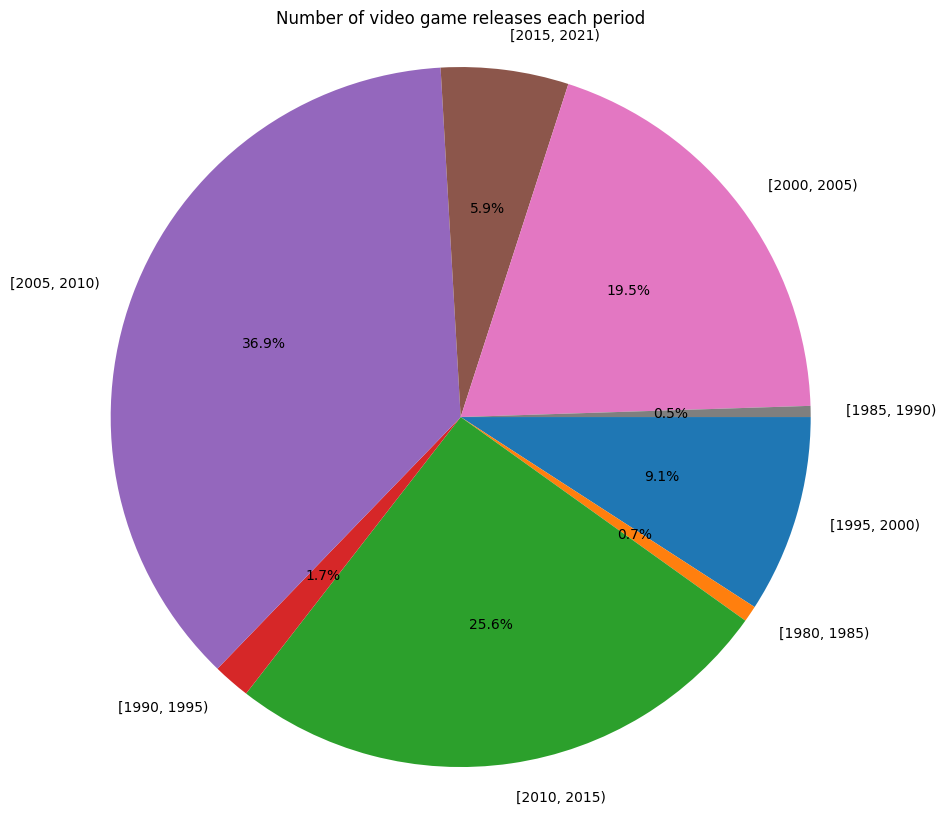

In [57]:
bins = [1980, 1985, 1990, 1995, 2000, 2005, 2010, 2015, 2021]
cats = pd.cut(df1['Year'], bins, right = False)
year = pd.DataFrame(pd.value_counts(cats))
years = year.sample(frac = 1)
fig = plt.figure(figsize=(20,10)), plt.pie(np.array(years).ravel(), labels = years.index, autopct = '%1.1f%%', counterclock = False);
plt.axis('square')
plt.title('Number of video game releases each period')

**3.What are the Sales of diffrent genres of Games in NA,EU,JP, Global and Other Markets?**

In [58]:
col = ['NA_Sales','EU_Sales', 'JP_Sales','Global_Sales','Other_Sales']
title = ['North America','Europe', 'Japan','Global','Other']
for i,c in enumerate(col):
    genre = df1.groupby('Genre').sum().sort_values(c,ascending=False).reset_index()[['Genre',c]]
    fig = px.bar(genre,x='Genre',y=c,title='Sales of different Genres of games in the {} market'.format(title[i]),
                labels={'Name':'Genre',c:title[i]+' Sales'},color="Genre")
    fig.show()

The Graph own describe in the Region of North America, Europe, Global and Other Market that the most sales of Action Genre and 2nd most are Sports while the case of Japan is different from others here the Role-playing sales most and 2nd most is Action.

**4.How much of the Number of Popular games available in Platform?**

/tmp/ipykernel_6580/3219477859.py:2: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




Text(0.5, 1.0, 'Number of popular games by platform')

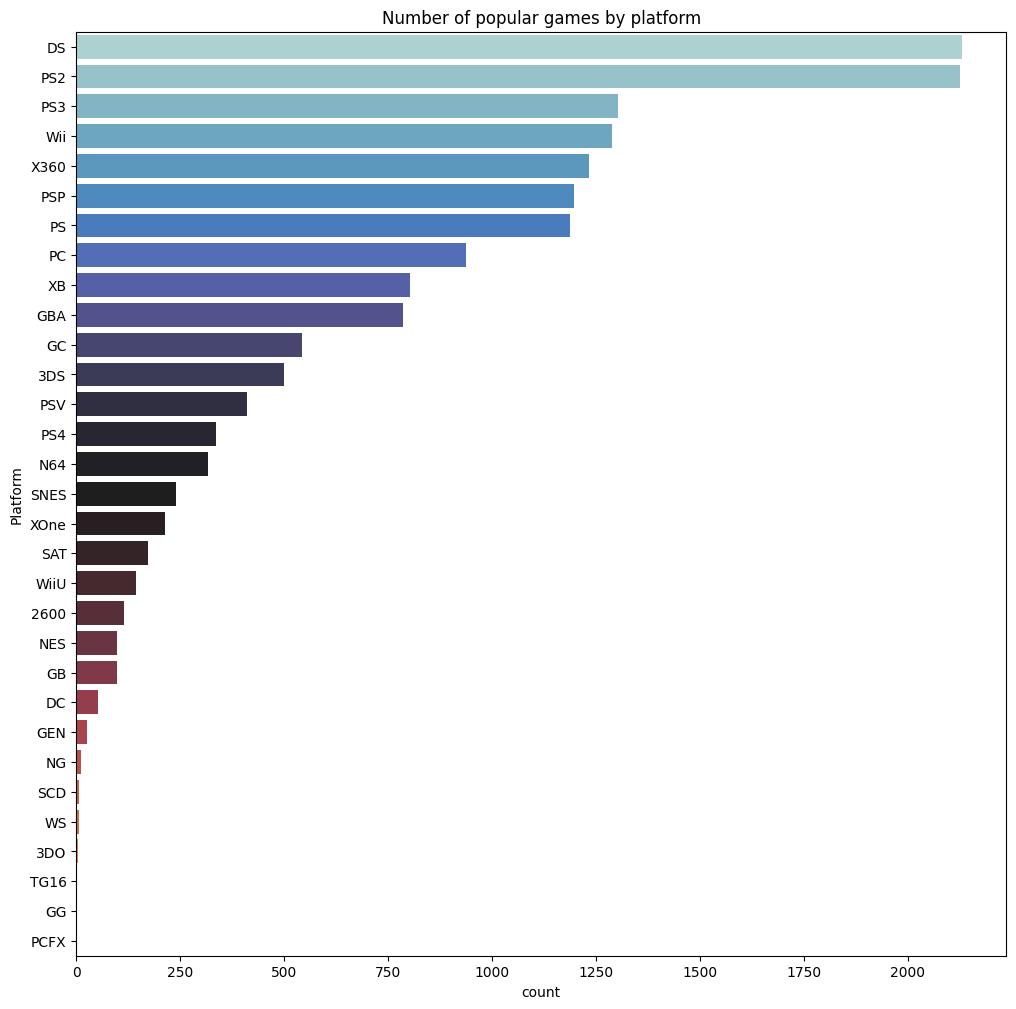

In [59]:
fig = plt.figure(figsize = (12,12))
sns.countplot(y='Platform',order = df1['Platform'].value_counts().index[0:31],data = df1,palette='icefire')
plt.title('Number of popular games by platform')

**5.What are the Top 10 Video Games Publishers in Diffrent Regions?**

In [60]:
# col = ['NA_Sales','EU_Sales', 'JP_Sales', 'Other_Sales']
# title = ['North America','Europe', 'Japan', 'Rest of the World']
col = ['NA_Sales','EU_Sales', 'JP_Sales','Global_Sales','Other_Sales']
title = ['North America','Europe', 'Japan','Global','Rest of the World']

for i,c in enumerate(col):
    top_10_publisher = df1.groupby('Publisher').sum().sort_values(c, ascending = False).head(10).reset_index()[['Publisher',c]]
    fig = px.bar(top_10_publisher, x='Publisher',y=c,title='Top 10 Video Game Publishers in {}'.format(title[i]),
       labels={'Name':'Game',c:title[i]}, color="Publisher")
    fig.show()

In the Region of North America ,Europe and Global Market the top 5 Publisher games are same which is Nintendo,Electronic Arts, Activision,Sony Computer Entertainment and Ubisoft but in japan the top 5 is like Nintendo,Namco Bandal Games,Konami,Sony and Capcom whereas in Rest of World the scenario is different here the top 5 is like Electronic Arts, Nintendo,Sony,Activision and Take-Two respectively.

**6.What are the Sales of Video games from year 1980-2020?**

In [61]:
fig=px.line(
    df.groupby(df.Year).sum().reset_index(),
    x='Year',
    y=['Global_Sales','NA_Sales','EU_Sales','JP_Sales','Other_Sales'],
    title='Sum of Sales by Year',
    )
fig.show()

Early Estimates shows that sales of video games from all around the world in year 1980 to 1995 not even cross 100 trademark but it rise slowly after the year 2000 the sales reach 100 trademark and grows continuosly in year 2005 to 2010. The year 2010 is highest among all the year but it declined after that in year 2015 and it again comes same line which was in year 1980.

**7.What are the Average Sales of Video games from year 1980-2020?**

In [62]:
fig=px.line(
    df.groupby(df.Year).mean(numeric_only=True).reset_index(),
    x='Year',
    y=['Global_Sales','NA_Sales','EU_Sales','JP_Sales','Other_Sales'],
    title='Average of Sales by Year',
    )
fig.show()

The Average of Global,North America,Japan,Europe and Other sales is highest in between the year 1989-1990. The line then start down after that and the average of all Sales in world lies on same line. But again some of Sales start in between the year 2015-2016.

**8.What are the Top 10 Best Selling Video Games around the World?**

In [63]:
# col = ['NA_Sales','EU_Sales', 'JP_Sales', 'Other_Sales']
# title = ['North America','Europe', 'Japan', 'Rest of the World']
col = ['NA_Sales','EU_Sales', 'JP_Sales','Global_Sales','Other_Sales']
title = ['North America','Europe', 'Japan','Global','Rest of the World']


for i,c in enumerate(col):
    sale_df = df1.groupby('Name').sum().sort_values(c,ascending=False).head(10).reset_index()[['Name',c]]
    fig = px.bar(sale_df,x='Name',y=c,title='The 10 best selling games in {}'.format(title[i]),
                labels={'Name':'Games Name',c:title[i]+' Sales'},color='Name')
    fig.show()

Conclusion

Wii Sports, made the most sales worldwide. This is echoed by both NA and EU regions. However, it is a different story in other regions, with Pokemon Red/Pokemon Blue dominating in Japan and Grand Theft Auto: San Andreas everywhere else

50% of top 10 games utilized the Wii Platform, making it one of the most successful consoles. This could be because of the fact that the Wii system was one of the most innovative consoles of its time by taking advantage of motion controls

Action, Sports and Misc are the most popular genres with high game titles as well as high global sales made

Nintendo snatched the spot for the Publisher that made the most global sales. Unsurprising is the fact that the top 10 games are all published by Nintendo!

In [64]:
top_sales = df1.sort_values(by=['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales'], ascending=False).head(10)

# ['NA_Sales', '', '', '']
dicts_name = {
    'NA_Sales' : "North America Sales ( In Millions)",
    'EU_Sales' : "Europe Sales ( In Millions)",
    'JP_Sales' : "Japan Sales ( In Millions)",
    'Other_Sales' : "Other Sales ( In Millions)",
}

for (key, title) in dicts_name.items():

    fig = px.sunburst(top_sales, path=['Genre', 'Publisher', 'Platform'], values=key, title= 'Top Selling by '+ title)

    fig.update_layout(
        grid= dict(columns=2, rows=2),
        margin = dict(t=40, l=2, r=2, b=5)
    )

    fig.show()

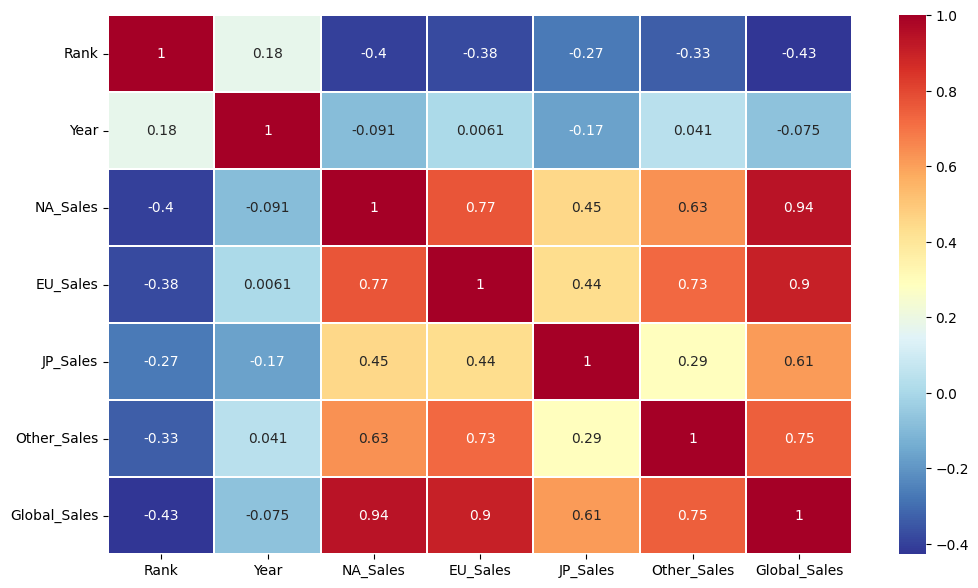

In [65]:
corr_ = df1.corr(numeric_only=True)

plt.figure(figsize=(12, 7))

sns.heatmap(corr_, annot=True, linewidths=.2, cmap='RdYlBu_r')

plt.show()

# Predictive Modelling — Leakage-Safe Evaluation

The earlier version used North American and European sales to predict global sales. Those regional values are components of global sales, so that setup leaks information from the target into the inputs and does not represent a genuine pre-release forecast.

This revised experiment uses only release metadata available before sales are observed: **platform, genre, publisher, and release year**. Categorical fields are one-hot encoded, missing values are imputed inside a pipeline, and preprocessing is refitted within each cross-validation fold.

The models are evaluated against a simple median baseline. Because sales are highly skewed, interpret MAE and RMSE alongside R²; a negative R² means the model performs worse than predicting the test-set mean. These results are a more defensible baseline, not proof that sales can be forecast accurately.

In [66]:
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Use only information that could be known around release time.
categorical_features = ["Platform", "Genre", "Publisher"]
numeric_features = ["Year"]
feature_columns = categorical_features + numeric_features
target_column = "Global_Sales"

df_model = df[feature_columns + [target_column]].copy()
df_model = df_model.dropna(subset=[target_column])
X = df_model[feature_columns]
y = df_model[target_column].astype(float)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Rows used for modelling: {len(df_model):,}")
print(f"Training rows: {len(X_train):,} | Holdout rows: {len(X_test):,}")
print(f"Features: {feature_columns}")
print("Regional sales columns are deliberately excluded to avoid target leakage.")

Rows used for modelling: 16,291
Training rows: 13,032 | Holdout rows: 3,259
Features: ['Platform', 'Genre', 'Publisher', 'Year']
Regional sales columns are deliberately excluded to avoid target leakage.


In [ ]:
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

preprocessor = ColumnTransformer(transformers=[
    ("categorical", categorical_transformer, categorical_features),
    ("numeric", numeric_transformer, numeric_features)
])

models = {
    "Median baseline": DummyRegressor(strategy="median"),
    "Ridge regression": Ridge(alpha=10.0),
    "Random forest": RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=1
    )
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "r2": "r2",
    "mae": "neg_mean_absolute_error",
    "mse": "neg_mean_squared_error"
}

results = []
fitted_models = {}

for model_name, estimator in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    cv_scores = cross_validate(
        pipeline, X_train, y_train,
        cv=cv, scoring=scoring, n_jobs=-1,
        return_train_score=False
    )

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        "Model": model_name,
        "CV R² (mean)": cv_scores["test_r2"].mean(),
        "CV MAE (mean)": -cv_scores["test_mae"].mean(),
        "CV RMSE (mean)": np.sqrt(-cv_scores["test_mse"].mean()),
        "Holdout R²": r2_score(y_test, predictions),
        "Holdout MAE": mean_absolute_error(y_test, predictions),
        "Holdout RMSE": np.sqrt(mean_squared_error(y_test, predictions))
    })
    fitted_models[model_name] = pipeline

model_results = pd.DataFrame(results).sort_values("Holdout RMSE")
model_results.round(3)

## Compare model performance

Use the **holdout metrics** for the final comparison. Cross-validation scores are calculated only on the training partition, and each fold learns its own preprocessing steps. The holdout set is not used to select model hyperparameters in this baseline comparison.

In [ ]:
display(model_results.round(3))

fig, ax = plt.subplots(figsize=(9, 4.5))
plot_results = model_results.sort_values("Holdout RMSE", ascending=True)
sns.barplot(data=plot_results, x="Holdout RMSE", y="Model", ax=ax)
ax.set_title("Holdout RMSE by model (lower is better)")
ax.set_xlabel("RMSE — global sales, in millions")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [ ]:
# Inspect the best model's predictions and errors on the untouched holdout set.
best_model_name = model_results.iloc[0]["Model"]
best_model = fitted_models[best_model_name]
best_predictions = best_model.predict(X_test)

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(y_test, best_predictions, alpha=0.35)
limit = max(float(y_test.max()), float(np.max(best_predictions)))
ax.plot([0, limit], [0, limit], linestyle="--")
ax.set_title(f"Actual vs predicted global sales — {best_model_name}")
ax.set_xlabel("Actual global sales (millions)")
ax.set_ylabel("Predicted global sales (millions)")
plt.tight_layout()
plt.show()

print(f"Best model by holdout RMSE: {best_model_name}")
print("Check the plotted spread and the metrics together; high-selling outliers can dominate RMSE.")

## Interpretation and limitations

- The median baseline provides a minimum benchmark; a more complex model should be judged by whether it improves on that baseline on unseen data.
- Platform, genre, publisher, and year are metadata proxies. The dataset does not contain marketing spend, price, review scores, distribution, or other factors that can influence sales.
- A random train/test split can place similar releases or titles from the same franchises in both partitions. A future extension could use a time-based split to test generalisation to later release years.
- Global sales are heavily right-skewed, so a small number of blockbuster titles may have a large effect on RMSE. MAE is useful as a complementary measure.
- Run the notebook from the top after opening it in Colab or a local Jupyter environment. The updated modelling cells have not been executed in this repository update, so fresh metric values will appear when you run them.

## Conclusion

This project explores historical video-game sales by genre, platform, publisher, release period, and region, then compares regression approaches using a leakage-aware evaluation design. The most useful next step is to turn the resulting charts and holdout metrics into a concise set of evidence-based recommendations, while being explicit about dataset limitations and uncertainty.